#Taller 5 de física computacional
Nombre del taller: Cálculo de π y convergencia

Estudiante: Cristian Fernando Castro Torres

#Parte A

In [20]:
%%writefile taller5_pi.f90
! Taller 5 -- Convergencia del estimador de pi por acierto y error.
! Salidas: convergencia.dat (N, media, desviación) y pendiente.dat (pendiente m).
program taller5_pi
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  integer, parameter :: M = 20                  ! corridas por cada N
  integer :: k, j, n_sem, u_dat, n_puntos
  integer(8) :: i, n_total, n_aciertos
  integer, allocatable :: semilla(:)
  real(dp) :: u, v, x, y, pi_est, suma, suma2, media, desv
  real(dp) :: X_k, Y_k, sx, sy, sxx, sxy, pendiente

  call random_seed(size=n_sem)
  allocate(semilla(n_sem))

  sx = 0.0_dp; sy = 0.0_dp; sxx = 0.0_dp; sxy = 0.0_dp; n_puntos = 0   ! sumas del ajuste
  open(newunit=u_dat,file='convergencia.dat',status='replace')
  do k = 2, 7                                   ! N = 10^2, ..., 10^7
     n_total = 10_8**k
     suma = 0.0_dp; suma2 = 0.0_dp              ! sumas sobre las M corridas
     do j = 1, M
        semilla = 1000*k + j                    ! una semilla distinta por corrida
        call random_seed(put=semilla)
        pi_est = -1.0_dp                        ! valor provisional

        ! TODO A1: obtenga pi_est con n_total puntos uniformes en el cuadrado (sección 2).
        n_aciertos = 0
        do i = 1, n_total
           call random_number(u)
           call random_number(v)
           x = 2.0_dp*u - 1.0_dp
           y = 2.0_dp*v - 1.0_dp
           if (x*x + y*y < 1.0_dp) n_aciertos = n_aciertos + 1
        end do
        pi_est = 4.0_dp * real(n_aciertos, dp) / real(n_total, dp)

        ! TODO A2: acumule lo necesario para la media y la desviación de las M corridas.
        suma = suma + pi_est
        suma2 = suma2 + (pi_est * pi_est)
     end do

     media = -1.0_dp; desv = -1.0_dp            ! valores provisionales

     ! TODO A3: calcule la media y la desviación estándar muestral de las M estimaciones.
     media = suma / real(M, dp)
     desv = sqrt((real(M, dp) / real(M - 1, dp)) * (suma2 / real(M, dp) - media * media))

     write(u_dat,'(i10,2es25.16e3)') n_total,media,desv
     print '(i10,2f12.6)', n_total,media,desv

     ! TODO A4: acumule lo necesario para ajustar log10(desv) contra log10(N).
     X_k = log10(real(n_total, dp))
     Y_k = log10(desv)
     sx = sx + X_k
     sy = sy + Y_k
     sxx = sxx + (X_k * X_k)
     sxy = sxy + (X_k * Y_k)
     n_puntos = n_puntos + 1
  end do
  close(u_dat)

  pendiente = -1.0_dp                           ! valor provisional

  ! TODO A5: calcule la pendiente del ajuste por mínimos cuadrados.
  pendiente = (real(n_puntos, dp) * sxy - sx * sy) / (real(n_puntos, dp) * sxx - sx * sx)

  open(newunit=u_dat,file='pendiente.dat',status='replace')
  write(u_dat,'(es25.16e3)') pendiente
  close(u_dat)
  print '(a,f9.4)', 'Pendiente de log10(s) contra log10(N): ', pendiente
end program taller5_pi

Overwriting taller5_pi.f90


#Visualización de la Parte A

       100    3.134000    0.161714
      1000    3.126600    0.049779
     10000    3.137260    0.015822
    100000    3.142696    0.003486
   1000000    3.141116    0.002166
  10000000    3.141530    0.000400
Pendiente de log10(s) contra log10(N):   -0.5079


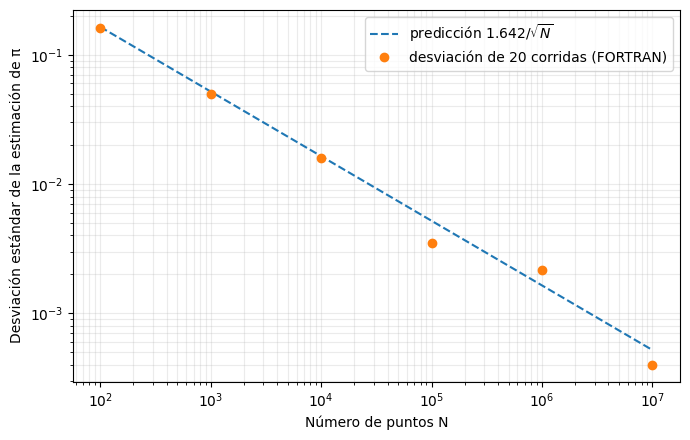

In [21]:
!gfortran -O3 taller5_pi.f90 -o taller5_pi && ./taller5_pi

import numpy as np
import matplotlib.pyplot as plt

# Lee N, media y desviación calculadas por el programa FORTRAN.
N, media, desv = np.loadtxt('convergencia.dat', ndmin=2).T

plt.figure(figsize=(7,4.5))
plt.loglog(N, 1.642/np.sqrt(N), '--', label=r'predicción $1.642/\sqrt{N}$')
if np.any(desv > 0):
    plt.loglog(N[desv > 0], desv[desv > 0], 'o', label='desviación de 20 corridas (FORTRAN)')
plt.xlabel('Número de puntos N')
plt.ylabel('Desviación estándar de la estimación de π')
plt.grid(True, which='both', alpha=.25)
plt.legend()
plt.tight_layout()
plt.savefig('convergencia_pi.png', dpi=180)
plt.show()

#Parte B

In [22]:
%%writefile taller5_seno.f90
! Taller 5 -- Integral de sin(x) en [0,pi/2) por valor medio y acierto y error.
! Salida: seno.dat (media_vm, desv_vm, media_ae, desv_ae).
program taller5_seno
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  integer, parameter :: N = 1000, R = 1000      ! muestras por corrida y repeticiones
  real(dp), parameter :: a = 0.0_dp, b = 2.0_dp*atan(1.0_dp), H = 1.0_dp
  integer :: rep, i, n_bajo, n_sem, u_dat
  integer, allocatable :: semilla(:)
  real(dp) :: u, v, x, y, suma_f, I_vm, I_ae
  real(dp) :: s_vm, s2_vm, s_ae, s2_ae, media_vm, desv_vm, media_ae, desv_ae

  ! El tamaño del arreglo de semilla depende de la implementación.
  call random_seed(size=n_sem)
  allocate(semilla(n_sem))
  semilla = 314
  call random_seed(put=semilla)                ! se fija una vez, antes de las R corridas

  s_vm = 0.0_dp; s2_vm = 0.0_dp; s_ae = 0.0_dp; s2_ae = 0.0_dp
  do rep = 1, R
     ! Valores provisionales reemplazados por la lógica de cálculo

     ! TODO B1: obtenga I_vm por valor medio usando N puntos (sección 4).
     suma_f = 0.0_dp
     do i = 1, N
        call random_number(u)
        x = a + (b - a)*u                  ! Transformación al intervalo [0, pi/2)
        suma_f = suma_f + sin(x)
     end do
     I_vm = (b - a) * suma_f / real(N, dp)

     ! TODO B2: obtenga I_ae por acierto y error en [a,b) x [0,H) (sección 4).
     n_bajo = 0
     do i = 1, N
        call random_number(u)
        call random_number(v)
        x = a + (b - a)*u                  ! Coordenada x en [0, pi/2)
        y = H * v                          ! Coordenada y en [0, 1)
        if (y < sin(x)) n_bajo = n_bajo + 1
     end do
     I_ae = (b - a) * H * real(n_bajo, dp) / real(N, dp)

     ! TODO B3: acumule las dos integrales y sus cuadrados para las R corridas.
     s_vm = s_vm + I_vm
     s2_vm = s2_vm + (I_vm * I_vm)

     s_ae = s_ae + I_ae
     s2_ae = s2_ae + (I_ae * I_ae)
  end do

  ! TODO B4: calcule media y desviación estándar muestral para cada método.
  media_vm = s_vm / real(R, dp)
  desv_vm = sqrt((real(R, dp) / real(R - 1.0_dp, dp)) * (s2_vm / real(R, dp) - media_vm * media_vm))

  media_ae = s_ae / real(R, dp)
  desv_ae = sqrt((real(R, dp) / real(R - 1.0_dp, dp)) * (s2_ae / real(R, dp) - media_ae * media_ae))

  ! Cuatro números sin encabezado para la lectura automática.
  open(newunit=u_dat,file='seno.dat',status='replace')
  write(u_dat,'(4es25.16e3)') media_vm,desv_vm,media_ae,desv_ae
  close(u_dat)
  print '(a,2f10.5)', 'Valor medio (media, desviacion): ',media_vm,desv_vm
  print '(a,2f10.5)', 'Acierto y error (media, desviacion): ',media_ae,desv_ae
end program taller5_seno

Overwriting taller5_seno.f90


In [23]:
!rm -f seno.dat
!gfortran -std=f2008 -O2 -fcheck=all -o taller5_seno taller5_seno.f90 && ./taller5_seno


Valor medio (media, desviacion):    0.99973   0.01529
Acierto y error (media, desviacion):    1.00009   0.02465


#Parte C

In [24]:
%%writefile taller5_lcg.f90
! Taller 5 -- pi por acierto y error con el LCG (57, 1, 256) en lugar de random_number.
! Salida: lcg.dat (N, pi_est).
program taller5_lcg
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  integer, parameter :: a_lcg = 57, c_lcg = 1, M_lcg = 256
  integer :: k, r, u_dat
  integer(8) :: i, n_total, n_aciertos
  real(dp) :: x, y, pi_est

  open(newunit=u_dat,file='lcg.dat',status='replace')
  do k = 2, 7                                   ! N = 10^2, ..., 10^7
     n_total = 10_8**k
     r = 10                                     ! semilla del LCG, la misma para cada N
     pi_est = -1.0_dp                           ! valor provisional

     ! TODO C1: obtenga pi_est con n_total puntos cuyas coordenadas salen del LCG (sección 5).
     n_aciertos = 0
     do i = 1, n_total
        ! --- Se avanza el estado para la coordenada X ---
        r = mod(a_lcg * r + c_lcg, M_lcg)
        ! Normalizamos de [0, M) a [0, 1) y luego desplazamos a [-1, 1)
        x = 2.0_dp * real(r, dp) / real(M_lcg, dp) - 1.0_dp

        ! --- Se avanza el estado de nuevo para la coordenada Y ---
        r = mod(a_lcg * r + c_lcg, M_lcg)
        y = 2.0_dp * real(r, dp) / real(M_lcg, dp) - 1.0_dp

        ! Evaluamos si cae dentro del círculo de radio 1
        if (x*x + y*y < 1.0_dp) n_aciertos = n_aciertos + 1
     end do
     ! Estimación final de pi para este valor de N
     pi_est = 4.0_dp * real(n_aciertos, dp) / real(n_total, dp)

     write(u_dat,'(i10,es25.16e3)') n_total,pi_est
     print '(i10,f12.6)', n_total,pi_est
  end do
  close(u_dat)
end program taller5_lcg

Overwriting taller5_lcg.f90


In [25]:
!rm -f lcg.dat
!gfortran -std=f2008 -O2 -fcheck=all -o taller5_lcg taller5_lcg.f90 && ./taller5_lcg

       100    3.040000
      1000    3.084000
     10000    3.093200
    100000    3.093720
   1000000    3.093740
  10000000    3.093750


#Parte D

1. Como vemos, la predicción cumple de muy buena manera el modelo empírico; por tanto, usaré este para calcular qué tan grande debería ser $N$ con un cálculo sencillo:          
$Error = \frac{1.642}{\sqrt{N}}$                    
Despejando la expresión, queda       
$N = \frac{{1.642^2}}{Error^2}$                            
Y reemplazando los valores, da:
$N = (1,642,000)^2 \approx 2.69 \times 10^{12}$        
Este número es demasiado grande como para justificar la precisión; de hecho, según la IA Gemini, a Colab le tomaría entre 2 y 8 horas ininterrumpidas correrlo.

2. El Valor Medio tiene menor dispersión porque promedia los valores reales de una función continua, cuya varianza es intrínsecamente menor que el salto binario (0 o 1) del Acierto y Error. Una sola corrida no basta, pues el azar podría favorecer al método menos preciso en un intento aislado; necesitas múltiples simulaciones para medir la verdadera anchura del error estadístico.
3. Porque el generador LCG utilizado tiene un módulo muy pequeño ($M=256$), lo que significa que posee un período máximo de solo 256 estados internos. Tras generar 256 valores, el generador agota su aleatoriedad y repite el ciclo infinitamente, haciendo que los pares $(x,y)$ colapsen en unas pocas líneas paralelas y dejen grandes vacíos geométricos. Aumentar $N$ no explora nuevas áreas del plano, sino que vuelve a colocar puntos exactamente sobre los mismos huecos equivocados de manera cíclica, convirtiendo lo que debería ser una fluctuación estadística en un sesgo sistemático insalvable.
4. Aunque el algoritmo lo resume como la fracción matemática $4 \times N_{\text{dentro}}/N$, lo que realmente calcula el código es el volumen bajo una superficie plana sobre un dominio bidimensional. Se está integrando numéricamente una función indicadora $f(x,y)$ sobre el cuadrado $[-1,1) \times [-1,1)$, donde $f(x,y) = 1$ si el punto pertenece al círculo ($x^2+y^2 < 1$) y $0$ si está fuera. Al contar aciertos aleatorios en 2D, estás estimando la integral doble que define esa área.

#PASS/FAIL

In [26]:
from pathlib import Path
import numpy as np

veredictos = []
def informar(nombre, condicion, detalle=''):
    estado = 'PASS' if condicion else 'FAIL'
    veredictos.append(bool(condicion))
    print(f'{estado} | {nombre}' + (f' — {detalle}' if detalle else ''))

def leer_salida(archivo, fuente, columnas):
    ruta, programa = Path(archivo), Path(fuente)
    if not programa.exists() or not ruta.exists():
        raise ValueError(f'Falta {archivo} o {fuente}; ejecute ambas celdas del programa.')
    if ruta.stat().st_mtime < programa.stat().st_mtime:
        raise ValueError(f'{archivo} es anterior a {fuente}; compile y ejecute otra vez.')
    datos = np.loadtxt(ruta, ndmin=2)
    if datos.shape[1] != columnas or not np.isfinite(datos).all():
        raise ValueError(f'Formato o valores incorrectos en {archivo}.')
    return datos

niveles = 10.0**np.arange(2, 8)                # N = 10^2, ..., 10^7

# --- Parte A: media y dispersión de 20 corridas; pendiente calculada en FORTRAN ---
try:
    filas = leer_salida('convergencia.dat','taller5_pi.f90',3)
    if filas.shape != (6,3) or not np.allclose(filas[:,0], niveles):
        raise ValueError('Se requieren seis filas con N=10^2,...,10^7.')
    n, media, desv = filas.T
    sigma = 1.642/np.sqrt(n)
    ok = (abs(media[4]-np.pi) < 6*sigma[4]/np.sqrt(20)
          and np.all((.45*sigma < desv) & (desv < 1.6*sigma)))
    informar('Convergencia de pi', ok,
             f'media(N=10^6)={media[4]:.6f}, s(N=10^6)={desv[4]:.6f}, predicción={sigma[4]:.6f}')
except Exception as error:
    informar('Convergencia de pi',False,str(error))

try:
    n, media, desv = leer_salida('convergencia.dat','taller5_pi.f90',3).T
    m = leer_salida('pendiente.dat','taller5_pi.f90',1)[0,0]
    if len(n) != 6 or not np.all(desv > 0):
        raise ValueError('convergencia.dat debe tener seis desviaciones positivas.')
    m_datos = np.polyfit(np.log10(n), np.log10(desv), 1)[0]
    informar('Pendiente del ajuste en FORTRAN', -.6 < m < -.4 and abs(m-m_datos) < 1e-4,
             f'm={m:.4f}, predicción=-0.5')
except Exception as error:
    informar('Pendiente del ajuste en FORTRAN',False,str(error))

# --- Parte B: integral de sin x por dos métodos ---
try:
    filas = leer_salida('seno.dat','taller5_seno.f90',4)
    if filas.shape != (1,4):
        raise ValueError('seno.dat debe contener media y desviación de cada método.')
    vm, svm, ae, sae = filas[0]
    n, repeticiones = 1000,1000
    sigma_vm = np.sqrt(np.pi**2/8-1)/np.sqrt(n)
    sigma_ae = np.sqrt(np.pi/2-1)/np.sqrt(n)
    ok_vm = (abs(vm-1)<6*sigma_vm/np.sqrt(repeticiones)
             and .65*sigma_vm < svm < 1.35*sigma_vm)
    ok_ae = (abs(ae-1)<6*sigma_ae/np.sqrt(repeticiones)
             and .65*sigma_ae < sae < 1.35*sigma_ae)
    informar('Integral 1D, valor medio',ok_vm,
             f'media={vm:.6f}, dispersión={svm:.6f}')
    informar('Integral 1D, acierto y error',ok_ae,
             f'media={ae:.6f}, dispersión={sae:.6f}')
except Exception as error:
    informar('Integral 1D, valor medio',False,str(error))
    informar('Integral 1D, acierto y error',False,'Revise el mismo programa.')

# --- Parte C: con el LCG la estimación se estanca lejos de pi ---
try:
    filas = leer_salida('lcg.dat','taller5_lcg.f90',2)
    if filas.shape != (6,2) or not np.allclose(filas[:,0], niveles):
        raise ValueError('Se requieren seis filas con N=10^2,...,10^7.')
    pi_lcg = filas[:,1]
    error_lcg = abs(pi_lcg - np.pi)
    ok = .02 < error_lcg[-1] < .2 and abs(pi_lcg[-1]-pi_lcg[-3]) < 1e-3
    informar('Generador deficiente', ok,
             f'|error| con N=10^5: {error_lcg[-3]:.4f}; con N=10^7: {error_lcg[-1]:.4f}')
except Exception as error:
    informar('Generador deficiente',False,str(error))

print(f'\nRESUMEN: {sum(veredictos)}/{len(veredictos)} PASS')
print('Las explicaciones científicas, los comentarios del código y el informe se revisan aparte.')

PASS | Convergencia de pi — media(N=10^6)=3.141116, s(N=10^6)=0.002166, predicción=0.001642
PASS | Pendiente del ajuste en FORTRAN — m=-0.5079, predicción=-0.5
PASS | Integral 1D, valor medio — media=0.999731, dispersión=0.015292
PASS | Integral 1D, acierto y error — media=1.000085, dispersión=0.024645
PASS | Generador deficiente — |error| con N=10^5: 0.0479; con N=10^7: 0.0478

RESUMEN: 5/5 PASS
Las explicaciones científicas, los comentarios del código y el informe se revisan aparte.
